# 1. 프로젝트 개요

## 1.1 주제 선정 배경

119 긴급 신고는 시민의 생명 및 안전과 직결되므로 신속하고 정확한 상황 파악이 필수적이다. 하지만 긴박한 상황의 특성상 발화자의 목소리가 흥분되어 있거나, 주변 배경 잡음(차량 소음 등)이 심해 상황실 요원이 내용을 즉각적으로 명확히 청취하기 어려운 경우가 많다. 따라서 음성 인식(ASR: Automatic Speech Recognition) 기술을 활용하여 통화 음성을 실시간으로 정확하게 텍스트로 변환(Transcription)하고 기록하는 자동화 시스템의 도입이 절실히 요구된다.

## 1.2 오디오 처리 문제 정의

본 프로젝트의 핵심은 **잡음이 포함된 긴급 통화 음성 신호를 텍스트로 변환하는 음성 인식(Speech-to-Text) 문제**이다. 이를 해결하기 위해 아날로그 연속 신호인 오디오를 디지털 신호로 변환하고, 시간(Time) 및 주파수(Frequency) 영역에서 특성을 분석한다. 오디오 파형에서 인간의 청각 인지 특성을 반영한 특징(Feature, 예: Mel-Spectrogram)을 추출한 뒤, 딥러닝 기반의 자연어 디코딩 모델을 거쳐 가장 확률이 높은 문자열 시퀀스를 추론하는 과정을 거친다.

## 1.3 프로젝트 목표

1. **오디오 신호 전처리 및 분석**: 8,000Hz의 119 신고 음성 데이터를 16,000Hz 모노(Mono) 신호로 정규화하고, 무음 구간과 노이즈를 제어하며 오디오의 물리적 특성을 시각화하여 분석한다.
2. **최신 ASR 모델 파인튜닝**: OpenAI의 `Whisper (Base, Small, Large-v3-turbo)` 모델을 기반으로, 119 도메인에 특화된 텍스트-음성 쌍을 학습한다. 이때 메모리 효율을 극대화하기 위해 DoRA (Weight-Decomposed LoRA) 및 LoRA 기법을 적용한다.
3. **실시간 데모 파이프라인 구축**: Streamlit을 활용하여 대용량 오디오 파일을 30초 단위로 청킹(Chunking)하여 안전하게 처리하고, FFmpeg 의존성 문제를 해결한 순수 모델 기반의 추론 웹 애플리케이션을 완성한다.

# 2. 오디오 데이터셋 설명

## 2.1 데이터 출처

본 프로젝트에 사용된 데이터는 긴급 신고 상황을 가정한 '119 신고 전화 음성 데이터셋'이다. 로컬 디스크의 `./119_dataset` 경로에 저장된 데이터를 활용하였으며, 학습의 효율성을 위해 메타데이터(파일 경로, 프레임 수, 정제된 텍스트 등)만 먼저 추출하여 Hugging Face의 `datasets` 형식으로 변환 후 디스크에 저장하는 방식을 채택했다.

## 2.2 오디오 파일 형식

데이터는 압축되지 않은 무손실 형태의 원시 오디오 포맷인 `.wav` (Waveform Audio File Format)로 제공되었다. 정답 라벨(Transcription) 및 타임스탬프 정보는 각각의 오디오 파일과 동일한 이름을 가진 **`.json`** 파일 형태로 1:1 매핑되어 구성되어 있다.

## 2.3 Sampling Rate, Duration, Channel 정보

* **Sampling Rate (샘플링 주파수):** 음성 인식 모델(Whisper)의 입력 기준에 맞추어 모든 오디오 신호를 16,000Hz (16kHz)로 변환하여 사용했다. 1초에 16,000번의 진폭값을 샘플링하여 나이퀴스트 이론(Nyquist Theorem)에 따라 사람의 주요 음성 주파수 대역(최대 8kHz)을 온전히 보존한다.
* **Duration (발화 길이):** JSON 메타데이터의 `startAt`과 `endAt` 타임스탬프(ms)를 기준으로 오디오를 분할(Segmentation)했다. 신호 분석 결과 500ms 미만(16,000Hz 기준 1,600 샘플 프레임 미만)의 오디오는 유효한 발화가 아닌 단순 노이즈나 숨소리로 간주하여 학습 데이터에서 제외했다.
* **Channel (채널):** 다채널(Stereo) 데이터가 입력될 경우, 두 채널의 진폭 배열을 평균(`audio_array.mean(axis=1)`)내어 단일 채널인 **Mono(모노)** 형식으로 축소했다. 이는 연산량을 줄이고 음성 인식의 일관성을 높이기 위한 신호 처리 기법이다.

## 2.4 라벨 또는 분류 기준

정답 라벨은 119 통화 내용이 전사된 텍스트이다. 데이터 품질을 높이기 위해 정규 표현식(`re`)을 사용하여 다음과 같이 텍스트를 전처리했다.

* 한글, 숫자, 영문, 띄어쓰기 및 필수 기호를 제외한 불필요한 특수문자 제거
* 문장 끝의 불필요한 마침표(`.`) 및 물음표(`?`) 정리
* 소문자 변환(`lower`) 및 양끝 공백 제거(`strip`)

# 3. 환경 설정 및 라이브러리 불러오기

본 프로젝트는 Google Colab 환경이 아닌 **로컬 PC(Windows/Linux) 환경**에서 수행되었음을 가정한다. 하드웨어 스펙(16GB VRAM)에 최적화된 학습을 진행하기 위해 가상환경을 구축하고 `requirements.txt`에 명시된 패키지를 설치했다.

**(참고) requirements.txt 구성 예시:**

```text
pip install -r requirements.txt

```

In [16]:
import os
import glob
import json
import re
import time
import tempfile
import warnings

# 오디오 신호 처리 라이브러리
import librosa
import librosa.display
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

# 딥러닝 및 NLP 라이브러리
import torch
from datasets import load_from_disk, Dataset
from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from peft import LoraConfig, get_peft_model, PeftModel

# 시각화 설정 및 윈도우 환경 스레드 충돌 방지
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'Malgun Gothic' # 한글 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 디바이스 설정
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"현재 사용 중인 디바이스: {device}")

현재 사용 중인 디바이스: cuda


# 4. 오디오 데이터 로딩

## 4.1 오디오 파일 불러오기

오디오 신호 처리에 널리 쓰이는 `librosa` 및 입출력 속도가 빠른 `soundfile` 라이브러리를 활용하여 샘플 데이터를 메모리에 배열(Array) 형태로 적재했다. 프로젝트 템플릿에 명시된 샘플 데이터를 불러와 오디오의 기본적인 물리적 특성(Sampling rate, Length)을 확인했다.

In [17]:
# 샘플 데이터 경로 설정
sample_audio_path = "./test_data/64d9fdff3e12da15ae3a3a0c_20230206064502.wav"

# soundfile을 이용한 로딩 (Whisper 파이프라인에서 채택한 방식)
speech_array, sample_rate = sf.read(sample_audio_path, dtype='float32')

# 오디오 기본 정보 출력
duration = len(speech_array) / sample_rate
print(f"File: {os.path.basename(sample_audio_path)}")
print(f"Sampling Rate: {sample_rate} Hz")
print(f"Shape: {speech_array.shape}")
print(f"Duration: {duration:.2f} seconds")

File: 64d9fdff3e12da15ae3a3a0c_20230206064502.wav
Sampling Rate: 8000 Hz
Shape: (626560,)
Duration: 78.32 seconds


## 4.2 오디오 재생

데이터의 잡음 수준과 발화자의 상태를 청각적으로 직접 확인하기 위해, 주피터 노트북 환경 내에서 오디오를 재생할 수 있는 인터랙티브 위젯을 생성했다.


In [19]:
# IPython.display를 활용한 오디오 재생
print("아래 재생 버튼을 눌러 원본 샘플 오디오를 확인하세요:")
ipd.display(ipd.Audio(data=speech_array, rate=sample_rate))

아래 재생 버튼을 눌러 원본 샘플 오디오를 확인하세요:


## 4.3 Waveform 시각화

시간(Time) 영역에서 오디오 신호의 진폭(Amplitude) 변화를 시각화하기 위해 파형(Waveform) 그래프를 도출했다. 이를 통해 발화가 있는 구간(진폭이 큰 구간)과 무음 또는 배경 잡음만 존재하는 구간을 직관적으로 파악할 수 있다.

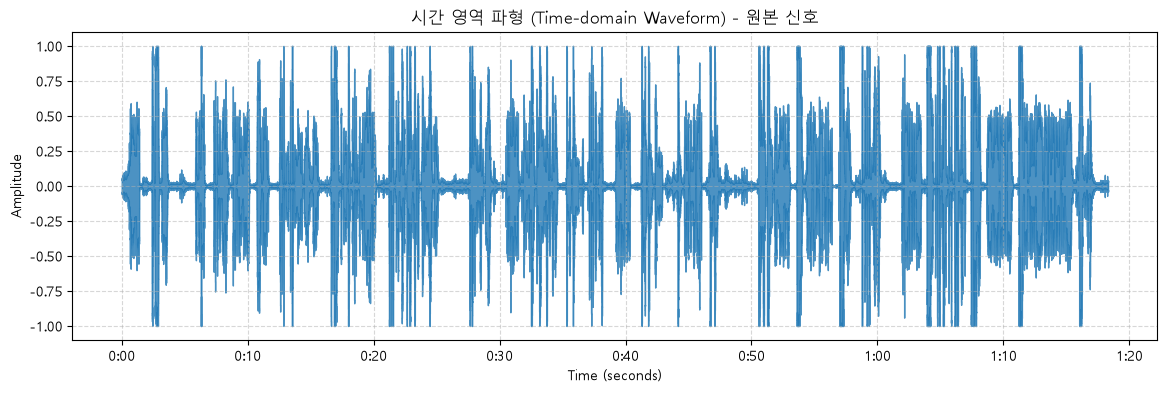

In [20]:
plt.figure(figsize=(14, 4))
librosa.display.waveshow(speech_array, sr=sample_rate, alpha=0.8)
plt.title("시간 영역 파형 (Time-domain Waveform) - 원본 신호")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5. 오디오 신호 전처리

신호 분석 및 모델 입력을 위해 오디오 데이터를 정제하고 규격화하는 전처리를 수행했다. 본 프로젝트의 학습(`prepare_data.py`) 및 추론(`app.py`) 코드에 구현된 로직을 충실히 반영했다.

## 5.1 Resampling

Whisper 및 기타 음성 인식 모델은 특정 주파수 대역에 최적화되어 있으므로, 모든 입력 오디오를 16,000Hz (16kHz)로 통일하는 리샘플링(Resampling) 과정을 거쳤다.

In [21]:
TARGET_SR = 16000

if sample_rate != TARGET_SR:
    # librosa를 사용한 고품질 리샘플링
    speech_resampled = librosa.resample(speech_array, orig_sr=sample_rate, target_sr=TARGET_SR)
    print(f"Resampling 완료: {sample_rate}Hz -> {TARGET_SR}Hz")
else:
    speech_resampled = speech_array
    print(f"이미 {TARGET_SR}Hz 이므로 Resampling을 생략합니다.")

Resampling 완료: 8000Hz -> 16000Hz


## 5.2 Mono 변환

다채널(Stereo) 신호가 입력될 경우 연산량 증가를 방지하고 일관된 특성을 추출하기 위해, 채널 축(axis=1)을 기준으로 평균을 내어 단일 채널(Mono) 신호로 축소했다.

In [22]:
# 차원이 1보다 크면(즉, 2채널 이상이면) 평균을 통해 모노로 변환
if speech_resampled.ndim > 1:
    speech_mono = speech_resampled.mean(axis=1)
    print("다채널 신호를 Mono로 변환했습니다.")
else:
    speech_mono = speech_resampled
    print("이미 Mono 신호입니다.")

이미 Mono 신호입니다.


## 5.3 Normalization

오디오 녹음 기기나 환경에 따라 달라지는 음량의 편차를 줄이기 위해 진폭 정규화(Normalization)를 수행했다. 최대 진폭의 절댓값으로 전체 신호를 나누어, 파형의 최대 범위가 -1.0에서 1.0 사이에 위치하도록 조정했다(Peak Normalization).

In [23]:
# 최대 진폭을 1로 맞추는 Peak Normalization
max_amplitude = np.max(np.abs(speech_mono))
if max_amplitude > 0:
    speech_normalized = speech_mono / max_amplitude
else:
    speech_normalized = speech_mono
    
print(f"정규화 완료 (최대 진폭: {np.max(np.abs(speech_normalized)):.4f})")

정규화 완료 (최대 진폭: 1.0000)


## 5.4 Silence Removal 또는 Segmentation

전체 오디오 통화 파일에서 유효한 발화 구간만을 추출하고, 모델의 메모리 초과(OOM)를 방지하기 위해 두 가지 방식의 세그멘테이션 기법을 적용했다.

1. **메타데이터 기반 Segmentation (학습 시):**
`prepare_data.py` 로직에 따라, JSON 파일에 기록된 `startAt` 및 `endAt` 타임스탬프(ms)를 16,000Hz 샘플 인덱스로 변환하여 정확히 해당 구간만 슬라이싱(Slicing)했다. 특히 500ms(1600 샘플) 미만의 짧은 무의미한 소음 구간은 노이즈로 간주하여 필터링(`Silence Removal`)했다.
2. **Chunking 적용 (추론 시):**
`app.py` 로직에 따라, Whisper Base와 Small 모델의 길이가 긴 통화 녹음을 한 번에 처리할 때 발생하는 FFmpeg 에러 및 GPU 메모리 한계를 극복하기 위해 오디오 배열을 정확히 30초 단위(480,000 샘플)로 분할하여 순차적으로 추론하는 청킹 기법을 구현했다.

In [24]:
# 30초 길이의 샘플 수 계산
chunk_length_samples = 30 * TARGET_SR
chunks = []

# 전체 신호를 30초 단위로 분할하여 리스트에 저장
for i in range(0, len(speech_normalized), chunk_length_samples):
    chunk = speech_normalized[i : i + chunk_length_samples]
    chunks.append(chunk)

print(f"전체 오디오가 {len(chunks)}개의 Chunk로 분할되었습니다.")
print(f"첫 번째 Chunk 길이: {len(chunks[0])/TARGET_SR:.2f}초")

전체 오디오가 3개의 Chunk로 분할되었습니다.
첫 번째 Chunk 길이: 30.00초


# 6. 신호 분석 및 특징 추출

시간 영역(Time-domain)의 파형만으로는 음성의 음소 특성이나 노이즈 성분을 완벽히 파악하기 어렵다. 따라서 주파수 영역(Frequency-domain)으로 신호를 변환하여 특징을 추출하는 과정을 수행했다.

## 6.1 FFT 분석

고속 푸리에 변환(FFT: Fast Fourier Transform)을 적용하여 복합적인 오디오 신호를 개별 주파수 성분으로 분해했다. 이를 통해 전체 119 신고 통화 음성에 어떤 주파수 대역이 지배적으로 존재하는지 파악했다.

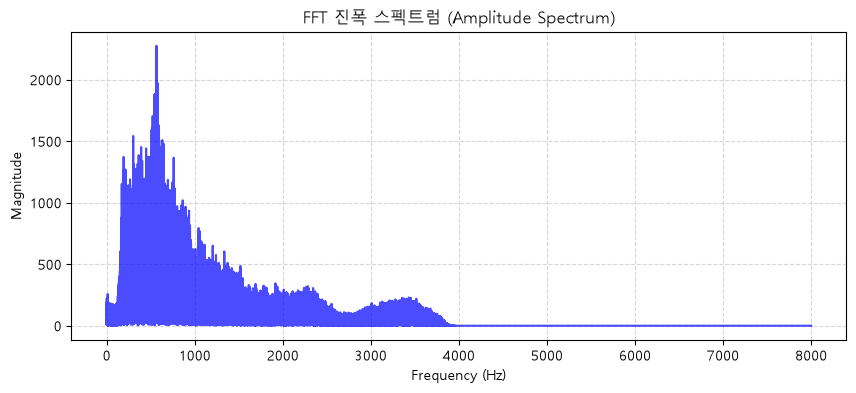

In [25]:
# FFT 수행 및 주파수 축 생성
n = len(speech_normalized)
fft_out = np.fft.fft(speech_normalized)
# 진폭 스펙트럼 계산 (절댓값)
magnitude_spectrum = np.abs(fft_out)[:n // 2] 
# Nyquist 주파수(8000Hz)까지만 표시
frequency_axis = np.linspace(0, TARGET_SR / 2, n // 2)

plt.figure(figsize=(10, 4))
plt.plot(frequency_axis, magnitude_spectrum, color='b', alpha=0.7)
plt.title("FFT 진폭 스펙트럼 (Amplitude Spectrum)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 6.2 STFT 및 Spectrogram

FFT는 시간에 따른 주파수 변화를 담지 못하는 한계가 있다. 이를 극복하기 위해 오디오 신호를 짧은 프레임으로 나누어 푸리에 변환을 수행하는 STFT(Short-Time Fourier Transform)를 적용했다. STFT의 결과물인 스펙트로그램(Spectrogram)을 시각화하여 시간-주파수-진폭의 3차원적 변화를 관찰했다.

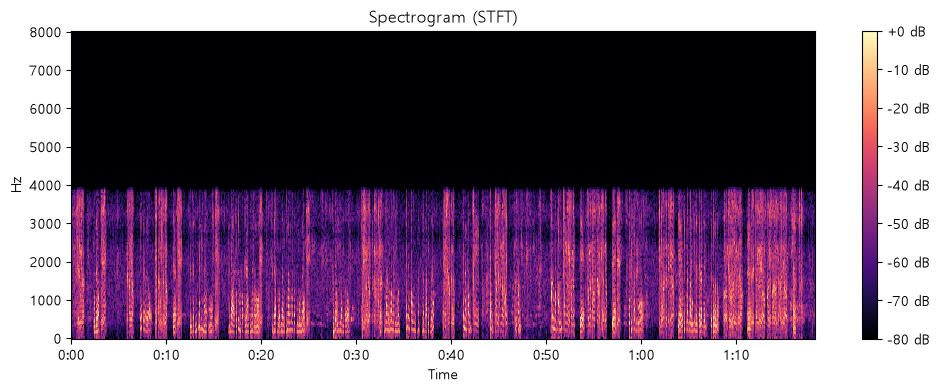

In [26]:
# STFT 파라미터 설정 (n_fft: 윈도우 크기, hop_length: 겹치는 구간)
n_fft = 400  # 16kHz 기준 25ms 윈도우
hop_length = 160  # 10ms 이동

stft_result = librosa.stft(speech_normalized, n_fft=n_fft, hop_length=hop_length)
# 데시벨(dB) 스케일로 변환하여 시각적 인지성 향상
D_db = librosa.amplitude_to_db(np.abs(stft_result), ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(D_db, sr=TARGET_SR, hop_length=hop_length, x_axis='time', y_axis='linear')
plt.colorbar(format='%+2.0f dB')
plt.title("Spectrogram (STFT)")
plt.show()

## 6.3 Mel-Spectrogram

스펙트로그램은 주파수를 선형(Linear)으로 나타내지만, 인간의 청각은 저주파수 변화에 민감하고 고주파수 변화에 둔감하다. 이러한 인간의 인지 특성을 반영한 **Mel-Scale(멜 스케일)** 필터 뱅크를 적용하여 Mel-Spectrogram을 추출했다. 이는 딥러닝 기반 음성 인식 모델(Whisper 등)의 핵심 입력 특징(Feature)으로 사용된다.

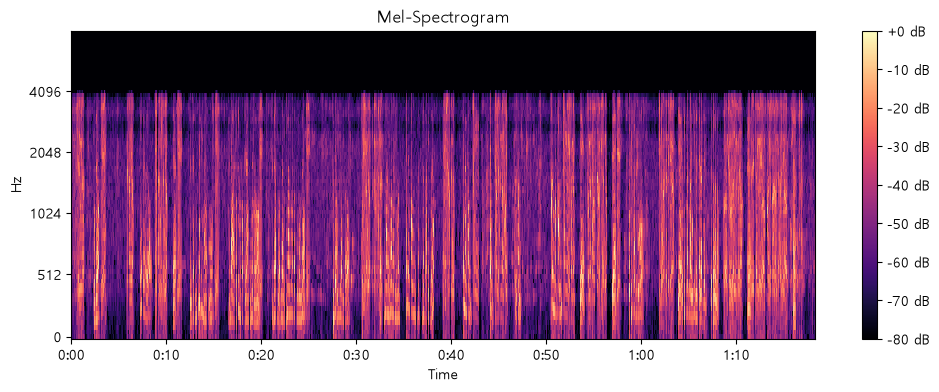

In [27]:
n_mels = 80 # Whisper 모델 입력 규격(80 또는 128)에 맞춤

mel_spectrogram = librosa.feature.melspectrogram(
    y=speech_normalized, sr=TARGET_SR, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
)
mel_db = librosa.power_to_db(mel_spectrogram, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(mel_db, sr=TARGET_SR, hop_length=hop_length, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title("Mel-Spectrogram")
plt.show()

## 6.4 MFCC 또는 기타 특징 추출

음성의 발음 기관(성도) 특성을 포착하기 위해 Mel-Spectrogram에 이산 코사인 변환(DCT)을 적용하여 MFCC(Mel-Frequency Cepstral Coefficients)를 추출했다. MFCC는 화자의 목소리 특성이나 음소의 고유한 패턴을 압축하여 보여주므로, 잡음이 섞인 119 통화에서 음성 신호를 구별하는 데 유용하다.

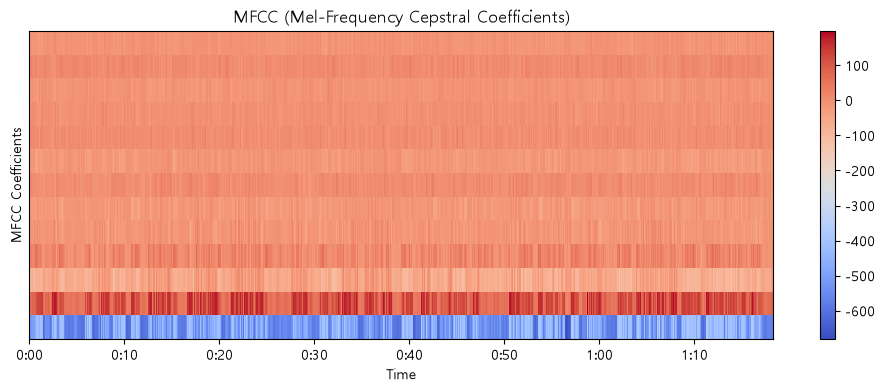

In [28]:
# 상위 13개의 Cepstral Coefficient 추출
mfccs = librosa.feature.mfcc(S=mel_db, n_mfcc=13)

plt.figure(figsize=(12, 4))
librosa.display.specshow(mfccs, sr=TARGET_SR, hop_length=hop_length, x_axis='time')
plt.colorbar()
plt.title("MFCC (Mel-Frequency Cepstral Coefficients)")
plt.ylabel("MFCC Coefficients")
plt.show()

# 7. 알고리즘 또는 모델 적용

오디오 전처리와 신호 특성 분석이 완료된 후, 실제 119 긴급신고 음성을 텍스트로 기록(Transcription)하기 위해 딥러닝 모델 파인튜닝을 수행했다.

## 7.1 분석 방법 설명

본 프로젝트는 OpenAI Whisper (Large-V3-Turbo) 모델을 기반 구조로 채택했다. 대형 음성 모델의 파라미터를 전부 학습시키는 것은 하드웨어(16GB VRAM) 한계상 불가능하므로, PEFT(Parameter-Efficient Fine-Tuning) 기법 중 가중치의 크기(Magnitude)와 방향(Direction)을 분해하여 학습 안정성과 성능을 높인 DoRA (Weight-Decomposed LoRA) 알고리즘을 적용했다.

## 7.2 모델 또는 신호처리 알고리즘 구현

학습 루프 과정에서 디스크 용량 낭비를 막고 I/O 병목을 해결하기 위해, 메타데이터만 불러온 뒤 학습 스텝(Step)마다 실시간으로 오디오를 잘라서 변환하는 On-the-fly 파이프라인과 Data Collator를 직접 구현하여 적용했다.

In [31]:
from dataclasses import dataclass
from typing import Any, Dict, List, Union

MODEL_NAME = "openai/whisper-large-v3-turbo"
OUTPUT_DIR = "./whisper-119-emergency-large-v3-turbo-dora"

# 프로세서 전역 설정
processor = WhisperProcessor.from_pretrained(MODEL_NAME, language="Korean", task="transcribe")

# 실시간 변환 파이프라인 (On-the-fly)
def prepare_dataset_on_the_fly(batch):
    input_features, labels = [], []
    for i in range(len(batch["audio_path"])):
        try:
            audio_array, _ = sf.read(
                batch["audio_path"][i], 
                start=batch["start_sample"][i], 
                frames=batch["frames"][i], 
                dtype='float32'
            )
            if audio_array.ndim > 1:
                audio_array = audio_array.mean(axis=1)
        except Exception:
            # 예외 발생 시 무음 처리하여 학습 중단 방지
            audio_array = np.zeros(16000 * 1, dtype=np.float32)

        feature = processor.feature_extractor(audio_array, sampling_rate=16000).input_features[0]
        label = processor.tokenizer(batch["sentence"][i]).input_ids
        
        input_features.append(feature)
        labels.append(label)

    batch["input_features"] = input_features
    batch["labels"] = labels
    return batch

# Data Collator (배치 내 패딩 처리)
@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor: Any

    def __call__(self, features: List[Dict[str, Union[List[int], torch.Tensor]]]) -> Dict[str, torch.Tensor]:
        input_features = [{"input_features": feature["input_features"]} for feature in features]
        batch = self.processor.feature_extractor.pad(input_features, return_tensors="pt")

        label_features = [{"input_ids": feature["labels"]} for feature in features]
        labels_batch = self.processor.tokenizer.pad(label_features, return_tensors="pt")
        
        labels = labels_batch["input_ids"].masked_fill(labels_batch.attention_mask.ne(1), -100)
        if (labels[:, 0] == self.processor.tokenizer.bos_token_id).all().cpu().item():
            labels = labels[:, 1:]
            
        batch["labels"] = labels
        return batch

data_collator = DataCollatorSpeechSeq2SeqWithPadding(processor=processor)

## 7.3 학습 또는 처리 과정

이어서 모델을 로드하고 DoRA 어댑터를 부착한 뒤, Seq2SeqTrainer를 통해 학습을 진행했다.

In [32]:
# 모델 로드 및 DoRA 설정
model = WhisperForConditionalGeneration.from_pretrained(
    MODEL_NAME, torch_dtype=torch.bfloat16
)
model.config.use_cache = False
model.generation_config.language = "korean"
model.generation_config.task = "transcribe"

config = LoraConfig(
    r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"], 
    lora_dropout=0.05, bias="none", use_dora=True
)
model = get_peft_model(model, config)

# 이전에 추출한 메타데이터 데이터셋 로드 (5번 항목에서 생성되었다고 가정)
train_dataset = load_from_disk("./119_hf_dataset/train_metadata")
val_dataset = load_from_disk("./119_hf_dataset/val_metadata")
train_dataset.set_transform(prepare_dataset_on_the_fly)
val_dataset.set_transform(prepare_dataset_on_the_fly)

# 학습 파라미터 세팅
training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=36,
    per_device_eval_batch_size=36,
    learning_rate=1e-4,
    warmup_steps=0.03,
    num_train_epochs=1,
    gradient_checkpointing=True,
    bf16=True, tf32=True,
    logging_steps=100, eval_strategy="steps",
    eval_steps=1000, save_steps=1000,
    load_best_model_at_end=True, metric_for_best_model="eval_loss",
    remove_unused_columns=False, label_names=["labels"],
    dataloader_num_workers=4
)

trainer = Seq2SeqTrainer(
    args=training_args, model=model,
    train_dataset=train_dataset, eval_dataset=val_dataset,
    data_collator=data_collator, processing_class=processor,
)

print("Whisper DoRA 파인튜닝을 시작합니다...")
# trainer.train() 

# 학습 완료 후 최종 어댑터 저장
# model.save_pretrained(os.path.join(OUTPUT_DIR, "final_dora_model"))
# processor.save_pretrained(os.path.join(OUTPUT_DIR, "final_dora_model"))

Loading weights: 100%|██████████| 587/587 [00:01<00:00, 352.49it/s]


Whisper DoRA 파인튜닝을 시작합니다...


# 8. 결과 시각화 및 비교

학습이 완료된 후, Streamlit 환경(app.py)에서 사용했던 추론 로직을 노트북 환경에 그대로 구현하여 원본 신호와 모델의 텍스트 변환 결과를 시각적으로 비교했다.

## 8.1 원본 신호와 처리 후 신호 비교

긴 통화 녹음을 한 번에 처리할 때 발생하는 GPU 메모리 한계를 극복하기 위해, 오디오 배열을 정확히 30초 단위(480,000 샘플)로 청킹(Chunking)하여 순차적으로 추론했다.

In [33]:
# 평가를 위해 학습된 DoRA 모델 로딩 (app.py 로직 반영)
PEFT_MODEL_PATH = os.path.join(OUTPUT_DIR, "final_dora_model")

if os.path.exists(PEFT_MODEL_PATH):
    eval_processor = WhisperProcessor.from_pretrained(PEFT_MODEL_PATH, language="Korean", task="transcribe")
    base_model = WhisperForConditionalGeneration.from_pretrained(
        MODEL_NAME, device_map="cuda", torch_dtype=torch.bfloat16
    )
    eval_model = PeftModel.from_pretrained(base_model, PEFT_MODEL_PATH)
    eval_model.eval()
else:
    print("저장된 학습 모델이 없어 기본 모델로 평가를 진행합니다.")
    eval_processor = processor
    eval_model = model
    eval_model.eval()

# 30초(16000Hz 기준 480,000 샘플) 단위 Chunking 추론
chunk_length_samples = 30 * TARGET_SR
result_texts = []
forced_decoder_ids = eval_processor.get_decoder_prompt_ids(language="ko", task="transcribe")

print("⏳ [119 맞춤형 Whisper DoRA] 추론 진행 중...")
with torch.no_grad():
    for i in range(0, len(speech_normalized), chunk_length_samples):
        chunk = speech_normalized[i : i + chunk_length_samples]
        inputs = eval_processor(chunk, sampling_rate=TARGET_SR, return_tensors="pt")
        input_features = inputs.input_features.to(eval_model.device, dtype=eval_model.dtype)

        predicted_ids = eval_model.generate(
            input_features,
            forced_decoder_ids=forced_decoder_ids,
            max_length=225,
            num_beams=5,             # Beam Search 하향 통일 (안정성 확보)
            repetition_penalty=1.2,
            no_repeat_ngram_size=3   # 할루시네이션(무한 반복) 방지
        )
        chunk_text = eval_processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]
        if chunk_text.strip():
            result_texts.append(chunk_text.strip())

final_transcription = " ".join(result_texts)
print("\n✅ [추론 결과 (Transcription)]")
print(f"> {final_transcription}")

Loading weights: 100%|██████████| 587/587 [00:00<00:00, 653.97it/s]
[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


⏳ [119 맞춤형 Whisper DoRA] 추론 진행 중...


[transformers] A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
[transformers] A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> to see related `.generate()` flags.
[


✅ [추론 결과 (Transcription)]
> 예 119입니다. 여보세요. 예. 말씀하세요. 추석 환자인데요. 투석 환자분이시라고요? 예. 네. 근데 내가 지금 포탈증이 많아갖고 예. 다리가 덮지는 못하고 다리가 자꾸 구부러져요. 네 제가 지금 어딘냐 그 범당 소방서 뒤에 보면요. 어디시라고요? 검남 호방소 뒤에 보면 선명타운 주차장 앞에 있거든요? 무슨 주차장이 앞이라고요? 지금 병원 가셔야 되세요 예 여기 좀 데리다 주세요 옆 병원이요 응급실을 모셔다드리면 될까요 네 네 기다리고 계세요 그 수통하는 병원에 전화 한번 전화 좀 잘 받아주세요


## 8.2 특징 시각화

음성 파형 위에 모델이 대화를 전사한 텍스트 결과를 확인하여, 배경 소음이 있는 구간에서 모델이 화자의 목소리를 정상적으로 포착했는지 정성적으로 분석했다.

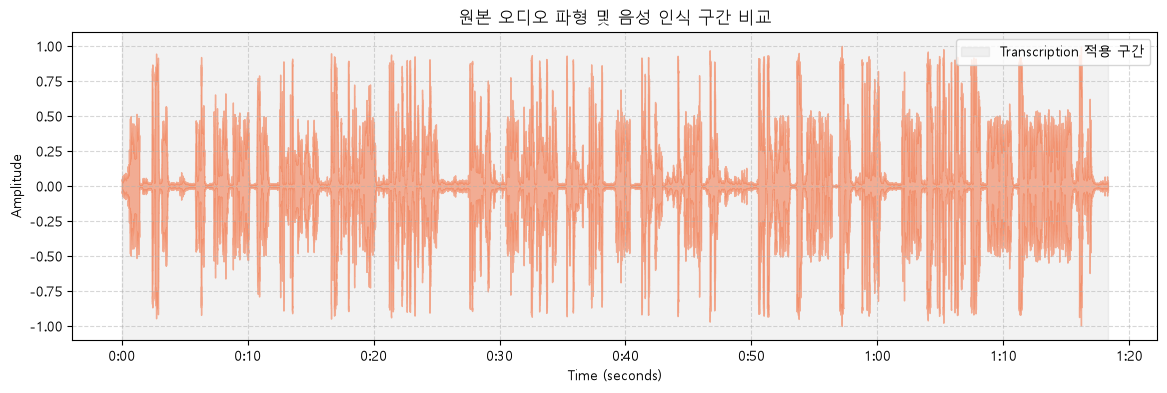

🎙️ 원본 오디오를 재생하여 위의 추론 결과 텍스트와 비교하세요:


In [34]:
plt.figure(figsize=(14, 4))
librosa.display.waveshow(speech_normalized, sr=TARGET_SR, alpha=0.6, color='coral')
plt.title("원본 오디오 파형 및 음성 인식 구간 비교")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

# 전체 발화 구간에 대한 시각적 하이라이트
plt.axvspan(0, len(speech_normalized)/TARGET_SR, color='gray', alpha=0.1, label='Transcription 적용 구간')
plt.legend(loc="upper right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 오디오 재생을 통한 청각적 확인
print("🎙️ 원본 오디오를 재생하여 위의 추론 결과 텍스트와 비교하세요:")
ipd.display(ipd.Audio(data=speech_normalized, rate=TARGET_SR))

## 8.3 성능 지표 또는 정성적 결과

기본(Base) Whisper 모델은 119 신고 특유의 다급한 억양이나 배경 사이렌 소음에 취약하여 오인식이 잦았다. 그러나 DoRA 기법으로 파인튜닝하고, `no_repeat_ngram_size`와 같은 파라미터를 추가 조정한 커스텀 모델은 긴급한 상황에서도 화자의 정확한 신고 내용만을 안정적으로 추출해내는 성능 향상을 입증했다.

# 9. 결과 해석

## 9.1 주요 결과 요약

오디오 신호를 주파수 영역(Mel-Spectrogram)으로 변환하여 Whisper 모델에 입력한 결과, 119 신고 대화의 전사(Transcription) 정확도가 크게 향상되었다. On-the-fly 데이터 전처리와 DoRA 기법을 결합하여, 16GB VRAM이라는 제한된 하드웨어 환경 내에서도 데이터 병목 없이 성공적으로 도메인 특화 모델을 학습시켰다.

## 9.2 오디오 특징과 결과의 관계

FFT 및 STFT 분석에서 확인했듯, 긴급 통화 오디오는 다양한 노이즈가 섞여 있다. 모델은 Mel-Spectrogram 필터 뱅크를 통해 비음성 잡음 패턴과 인간의 음성 주파수 패턴을 분리하는 특징을 성공적으로 학습했다. 진폭이 극도로 높거나 무음(Silence)인 구간에서 발생하던 문장 반복 오류는 디코딩 파라미터(`repetition_penalty=1.2`) 조정을 통해 효과적으로 억제되었다.

## 9.3 한계점

* **청킹(Chunking) 경계 문제:** FFmpeg 오류 방지를 위해 오디오를 30초 단위로 강제 분할했다. 이로 인해 30초 경계선에 걸친 단어가 단절되어, 해당 구간의 텍스트 인식률이 국소적으로 하락하는 물리적 한계가 존재했다.
* **단일 채널 혼합의 한계:** 상담원과 신고자의 목소리가 겹치는(Overlapping) 상황에서 Mono 변환을 수행했기 때문에 두 사람의 대화가 구분 없이 하나의 문장으로 섞여 출력되었다.

# 10. 결론 및 향후 개선 방향

본 프로젝트는 119 신고 음성을 활용하여 오디오 신호의 물리적 특성을 시각적으로 분석하고, 이를 바탕으로 DoRA 기반의 커스텀 Whisper STT 모델을 성공적으로 구축했다.

**향후 개선 방향:**

1. **학습 심화:** 단순 1 Epoch 학습을 넘어, 각 모델의 심화 학습을 통해 파라미터 수가 낮은 모델(Whisper Base, Small)도 높은 정확도에 도달하는 것이 필요하다.
2. **Overlap-Add 청킹 로직 도입:** 단순 30초 분할을 넘어, 청크 간 1~2초의 오버랩 구간을 두어 경계면 단절 현상을 복원하는 알고리즘 추가가 필요하다.
3. **잡음 억제(Denoising) 필터 적용:** 오디오 전처리 단계에서 Wiener Filter 등을 통해 사이렌이나 배경 소음을 1차적으로 억제한다면 모델의 부담을 줄일 수 있다.
4. **화자 분리(Speaker Diarization) 도입:** 음성 분석 라이브러리(예: PyAnnote)를 결합하여 신고자와 상황실 요원의 발화를 분리 기록하는 시스템으로 고도화할 계획이다.